# IoU und Non-Maximum Suppression

Wir implementieren die Grundbausteine der Objekterkennung selbst:

1. Umrechnung zwischen dem Format **xyxy** und dem **YOLO-Format**
2. **Intersection over Union (IoU)**
3. **Non-Maximum Suppression (NMS)**

Anschließend wenden wir NMS auf die Vorhersagen eines Münzbildes an und berechnen den Betrag für den **KI-Geldzähler**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

## 1. Umrechnung der Box-Formate

- **xyxy:** $(x_1, y_1, x_2, y_2)$ in Pixeln, obere linke und untere rechte Ecke
- **YOLO:** $(x_c, y_c, w, h)$, Mittelpunkt, Breite und Höhe, normiert auf Bildbreite $W$ und Bildhöhe $H$

In [2]:
def xyxy_to_yolo(box, W, H):
    """Pixel-Box (x1, y1, x2, y2) -> normierte YOLO-Box (xc, yc, w, h)."""
    x1, y1, x2, y2 = box
    xc = (x1 + x2) / (2 * W)
    yc = (y1 + y2) / (2 * H)
    w = (x2 - x1) / W
    h = (y2 - y1) / H
    return xc, yc, w, h


def yolo_to_xyxy(box, W, H):
    """Normierte YOLO-Box (xc, yc, w, h) -> Pixel-Box (x1, y1, x2, y2)."""
    xc, yc, w, h = box
    x1 = (xc - w / 2) * W
    y1 = (yc - h / 2) * H
    x2 = (xc + w / 2) * W
    y2 = (yc + h / 2) * H
    return x1, y1, x2, y2

In [3]:
# Beispiel aus der Vorlesung: 2-€-Münze in einem Bild mit 1280 x 960 Pixeln
yolo = xyxy_to_yolo((512, 384, 640, 512), W=1280, H=960)
print("YOLO-Format:", np.round(yolo, 3))
print("Zeile in der Labeldatei: 7 " + " ".join(f"{v:.3f}" for v in yolo))

restored = yolo_to_xyxy(yolo, W=1280, H=960)
print("Zurück nach xyxy:", np.round(restored, 1))

YOLO-Format: [0.45  0.467 0.1   0.133]
Zeile in der Labeldatei: 7 0.450 0.467 0.100 0.133
Zurück nach xyxy: [512. 384. 640. 512.]


## 2. Intersection over Union

$$\operatorname{IoU}(A, B) = \frac{|A \cap B|}{|A| + |B| - |A \cap B|}$$

In [4]:
def area(r):
    return (r[2] - r[0]) * (r[3] - r[1])


def iou(a, b):
    """IoU zweier Boxen im Format xyxy."""
    w = min(a[2], b[2]) - max(a[0], b[0])
    h = min(a[3], b[3]) - max(a[1], b[1])
    inter = max(0, w) * max(0, h)
    union = area(a) + area(b) - inter
    return inter / union

In [5]:
# Rechenbeispiel aus der Vorlesung
print("Beispiel:  ", iou((100, 100, 200, 200), (120, 110, 220, 210)))   # erwartet 0.5625

# Gleicher Versatz von 4 Pixeln, unterschiedlich große Münzen
print("2-€-Münze: ", round(iou((0, 0, 100, 100), (4, 4, 104, 104)), 3))  # erwartet ca. 0.855
print("1-ct-Münze:", round(iou((0, 0, 20, 20), (4, 4, 24, 24)), 3))      # erwartet ca. 0.471

# Keine Überlappung
print("Getrennt:  ", iou((0, 0, 10, 10), (20, 20, 30, 30)))              # erwartet 0.0

Beispiel:   0.5625
2-€-Münze:  0.855
1-ct-Münze: 0.471
Getrennt:   0.0


## 3. Non-Maximum Suppression

Greedy-Verfahren: Die Box mit der höchsten Confidence wird behalten, alle Boxen mit $\operatorname{IoU} \geq \tau$ zu ihr werden entfernt. Das wird wiederholt, bis keine Box mehr übrig ist.

In [6]:
def nms(boxes, scores, tau=0.5):
    """Gibt die Indizes der behaltenen Boxen zurück."""
    order = list(np.argsort(scores)[::-1])
    keep = []
    while order:
        best = order.pop(0)
        keep.append(best)
        b = boxes[best]
        order = [i for i in order
                 if iou(b, boxes[i]) < tau]
    return keep

NMS wird **pro Klasse** ausgeführt: Eine 1-€-Münze soll keine überlappende 2-€-Box löschen.

In [7]:
def nms_per_class(boxes, scores, classes, tau=0.5):
    keep = []
    for c in np.unique(classes):
        idx = np.where(classes == c)[0]
        kept = nms(boxes[idx], scores[idx], tau)
        keep.extend(idx[kept])
    return sorted(keep)

## 4. Vorhersagen für ein Münzbild

Ein Detektor hat für ein Bild mit $800 \times 600$ Pixeln die folgenden Rohvorhersagen geliefert (vor Schwellenwert und NMS). Auf dem Bild liegen tatsächlich **2 €, 20 ct, zwei 1-€-Münzen, die sich überlappen, 10 ct und 5 ct**, zusammen also **4,35 €**.

In [8]:
VALUES = {"5ct": 0.05, "10ct": 0.10, "20ct": 0.20, "1eur": 1.00, "2eur": 2.00}
NAMES = list(VALUES)          # Klassen-ID = Position in der Liste

# Ground Truth: Mittelpunkt, Radius, Klasse
coins = [((200, 200), 60, "2eur"), ((450, 180), 52, "20ct"),
           ((300, 420), 54, "1eur"), ((340, 430), 54, "1eur"),
           ((620, 400), 46, "10ct"), ((650, 150), 50, "5ct")]

# Rohvorhersagen: (x1, y1, x2, y2), Confidence, Klasse
predictions = [
    ((142, 138, 262, 258), 0.93, "2eur"),
    ((160, 160, 280, 280), 0.71, "2eur"),   # Doppeltreffer
    ((398, 128, 502, 232), 0.88, "20ct"),
    ((248, 364, 356, 472), 0.86, "1eur"),
    ((284, 378, 392, 486), 0.79, "1eur"),   # zweite, echte 1-€-Münze
    ((232, 350, 346, 462), 0.47, "1eur"),   # Doppeltreffer
    ((574, 354, 666, 446), 0.66, "10ct"),
    ((590, 368, 684, 462), 0.41, "10ct"),   # Doppeltreffer
    ((600, 100, 700, 200), 0.52, "5ct"),
    ((100, 480, 150, 530), 0.18, "20ct"),   # Knopf, Fehlalarm
]

boxes = np.array([v[0] for v in predictions], dtype=float)
scores = np.array([v[1] for v in predictions])
classes = np.array([NAMES.index(v[2]) for v in predictions])
print(len(boxes), "Rohvorhersagen")

10 Rohvorhersagen


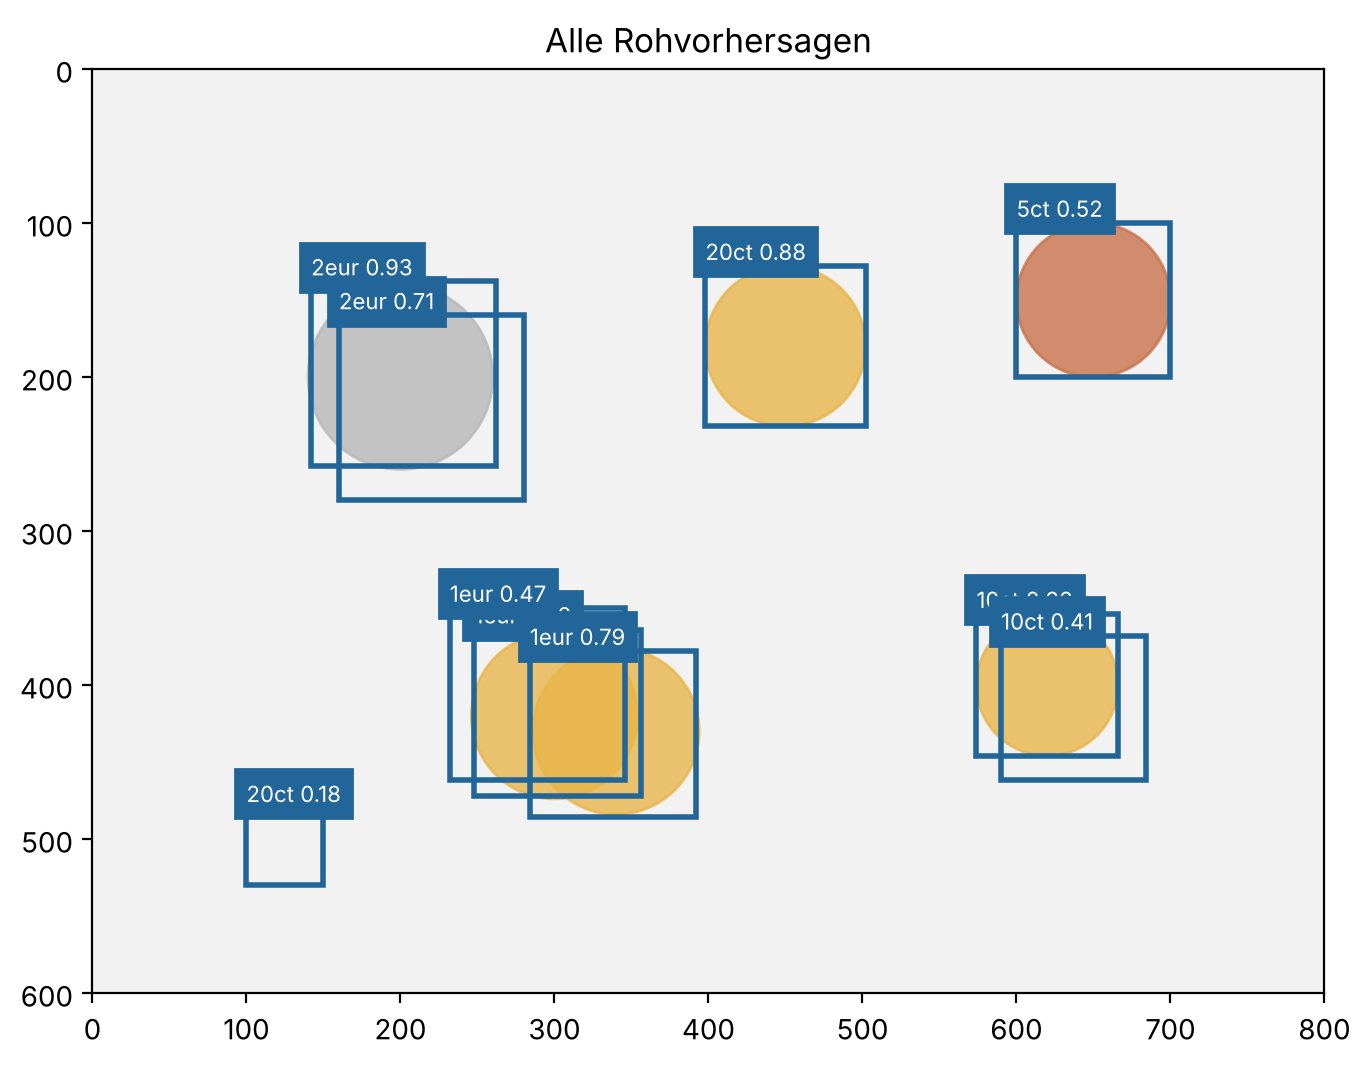

In [9]:
COIN_COLORS = {"5ct": "#C8734B", "10ct": "#E8B54A", "20ct": "#E8B54A",
               "1eur": "#E8B54A", "2eur": "#B8B8B8"}


def draw_predictions(keep=None, title=""):
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlim(0, 800)
    ax.set_ylim(600, 0)                       # Ursprung oben links
    ax.set_facecolor("#F2F2F2")
    for (cx, cy), r, k in coins:
        ax.add_patch(patches.Circle((cx, cy), r, color=COIN_COLORS[k], alpha=0.8))
    idx = range(len(boxes)) if keep is None else keep
    for i in idx:
        x1, y1, x2, y2 = boxes[i]
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                       fill=False, lw=2, ec="#226699"))
        ax.text(x1, y1 - 4, f"{NAMES[classes[i]]} {scores[i]:.2f}",
                color="white", fontsize=8, backgroundcolor="#226699")
    ax.set_title(title)
    ax.set_aspect("equal")
    plt.show()


draw_predictions(title="Alle Rohvorhersagen")

## 5. Der KI-Geldzähler

Zuerst werden alle Vorhersagen unter dem Schwellenwert `conf` verworfen, danach folgt NMS pro Klasse. Berechnen Sie den Betrag für $\tau \in \{0{,}3;\ 0{,}5;\ 0{,}7\}$.

In [10]:
def total(keep):
    return sum(VALUES[NAMES[classes[i]]] for i in keep)


conf = 0.25
candidates = np.where(scores >= conf)[0]

for tau in [0.3, 0.5, 0.7]:
    kept = nms_per_class(boxes[candidates], scores[candidates],
                          classes[candidates], tau)
    keep = candidates[kept]
    print(f"tau = {tau}: {len(keep)} Münzen, Summe = {total(keep):.2f} €")

tau = 0.3: 5 Münzen, Summe = 3.35 €
tau = 0.5: 6 Münzen, Summe = 4.35 €
tau = 0.7: 9 Münzen, Summe = 7.45 €


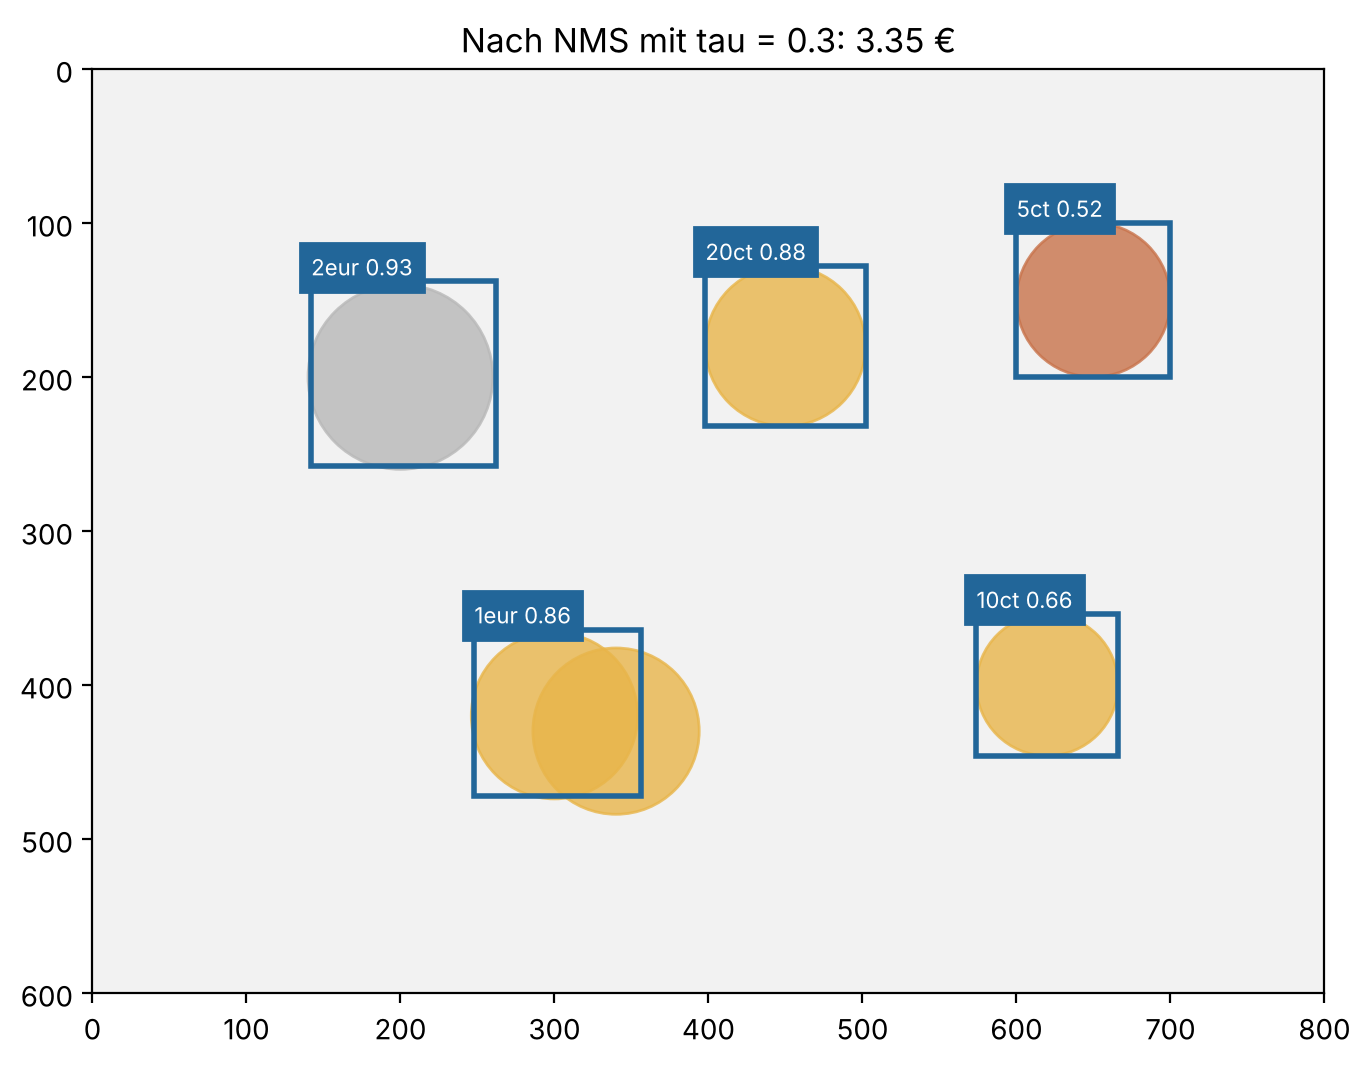

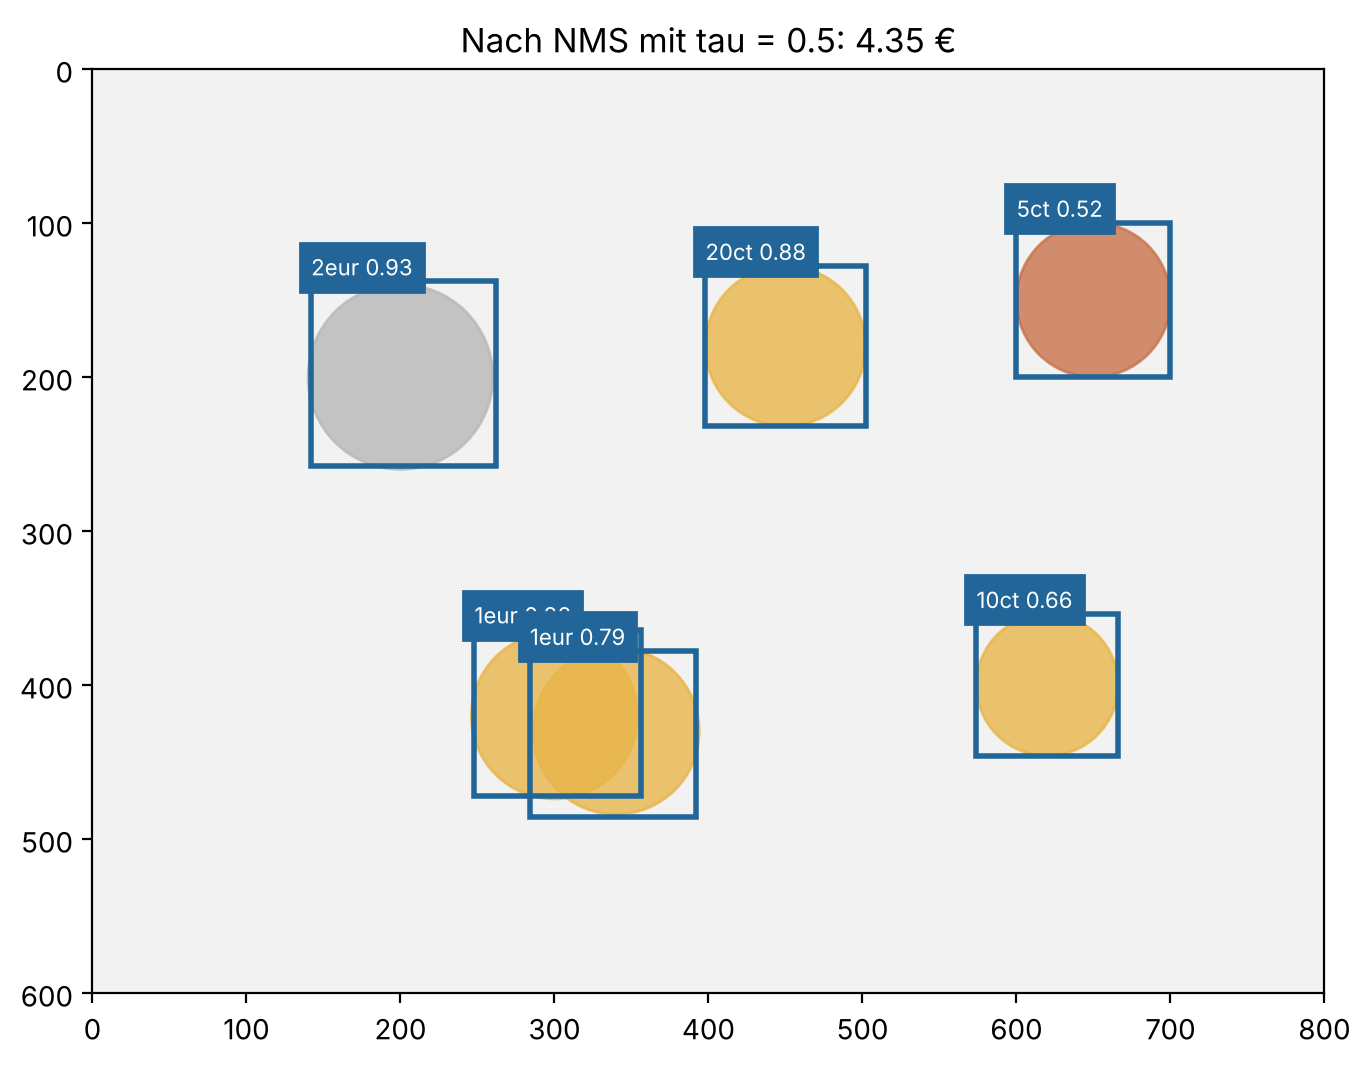

In [11]:
for tau in [0.3, 0.5]:
    keep = candidates[nms_per_class(boxes[candidates], scores[candidates],
                                     classes[candidates], tau)]
    draw_predictions(keep, f"Nach NMS mit tau = {tau}: {total(keep):.2f} €")

In [12]:
# Warum? Die entscheidenden IoU-Werte
print(f"2 € mit Doppeltreffer:        {iou(boxes[0], boxes[1]):.2f}")
print(f"10 ct mit Doppeltreffer:      {iou(boxes[6], boxes[7]):.2f}")
print(f"1 € mit Doppeltreffer:        {iou(boxes[3], boxes[5]):.2f}")
print(f"Die beiden echten 1-€-Münzen: {iou(boxes[3], boxes[4]):.2f}")

2 € mit Doppeltreffer:        0.53
10 ct mit Doppeltreffer:      0.52
1 € mit Doppeltreffer:        0.65
Die beiden echten 1-€-Münzen: 0.41
